# Healthcare Insurance Cost Prediction using Linear Regression

## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics

print("Libraries imported successfully")

Libraries imported successfully


## 2. Load the dataset

In [2]:
file_path = '../data/medical_insurance_cost_dataset_enhanced.csv'
df = pd.read_csv(file_path)
print(df.head())

  customer_id  age  gender   bmi  children smoker     region occupation  \
0   MIC100001   56    Male  25.2         2    Yes  Northeast     Driver   
1   MIC100002   29    Male  25.7         1    Yes  Northwest     Doctor   
2   MIC100003   20    Male  30.1         1     No    Central    Teacher   
3   MIC100004   59  Female  18.2         1     No  Northeast   Engineer   
4   MIC100005   61    Male  31.2         5    Yes  Northwest      Nurse   

   annual_income_usd exercise_level  ...  hospitalizations_last_year  \
0              77885       Moderate  ...                           0   
1              18000           High  ...                           0   
2              85811            Low  ...                           0   
3              18000       Moderate  ...                           0   
4              42331       Moderate  ...                           0   

   alcohol_consumption_per_week  insurance_plan  annual_medical_cost_usd  \
0                            13         

## 3. Check the data

In [3]:
print("Rows and columns:", df.shape)
print()
print(df.info())

Rows and columns: (7500, 22)

<class 'pandas.DataFrame'>
RangeIndex: 7500 entries, 0 to 7499
Data columns (total 22 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   customer_id                   7500 non-null   str    
 1   age                           7500 non-null   int64  
 2   gender                        7500 non-null   str    
 3   bmi                           7500 non-null   float64
 4   children                      7500 non-null   int64  
 5   smoker                        7500 non-null   str    
 6   region                        7500 non-null   str    
 7   occupation                    7500 non-null   str    
 8   annual_income_usd             7500 non-null   int64  
 9   exercise_level                7500 non-null   str    
 10  chronic_diseases              7500 non-null   int64  
 11  doctor_visits_per_year        7500 non-null   int64  
 12  hospitalizations_last_year    7500 non-null

In [4]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values: 0
Duplicate rows: 0


In [5]:
print(df['annual_medical_cost_usd'].describe())

count     7500.000000
mean     17912.526807
std       7574.460081
min       1500.000000
25%      12385.620000
50%      16361.925000
75%      22555.107500
max      49332.680000
Name: annual_medical_cost_usd, dtype: float64


## 4. Explore the data

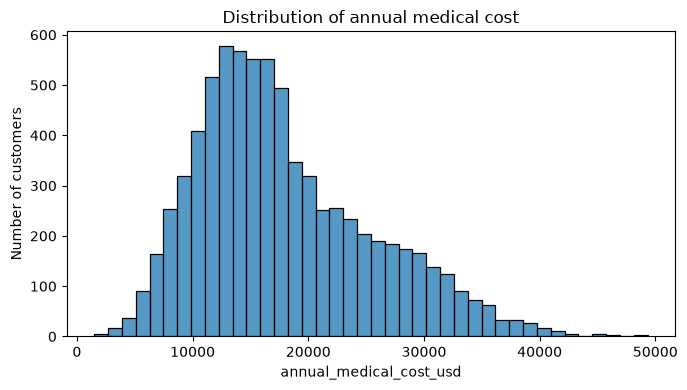

In [6]:
plt.figure(figsize=(7, 4))
sns.histplot(df['annual_medical_cost_usd'], bins=40)
plt.xlabel('annual_medical_cost_usd')
plt.ylabel('Number of customers')
plt.title('Distribution of annual medical cost')
plt.tight_layout()
plt.savefig('../outputs/target_distribution.png', dpi=150)
plt.show()

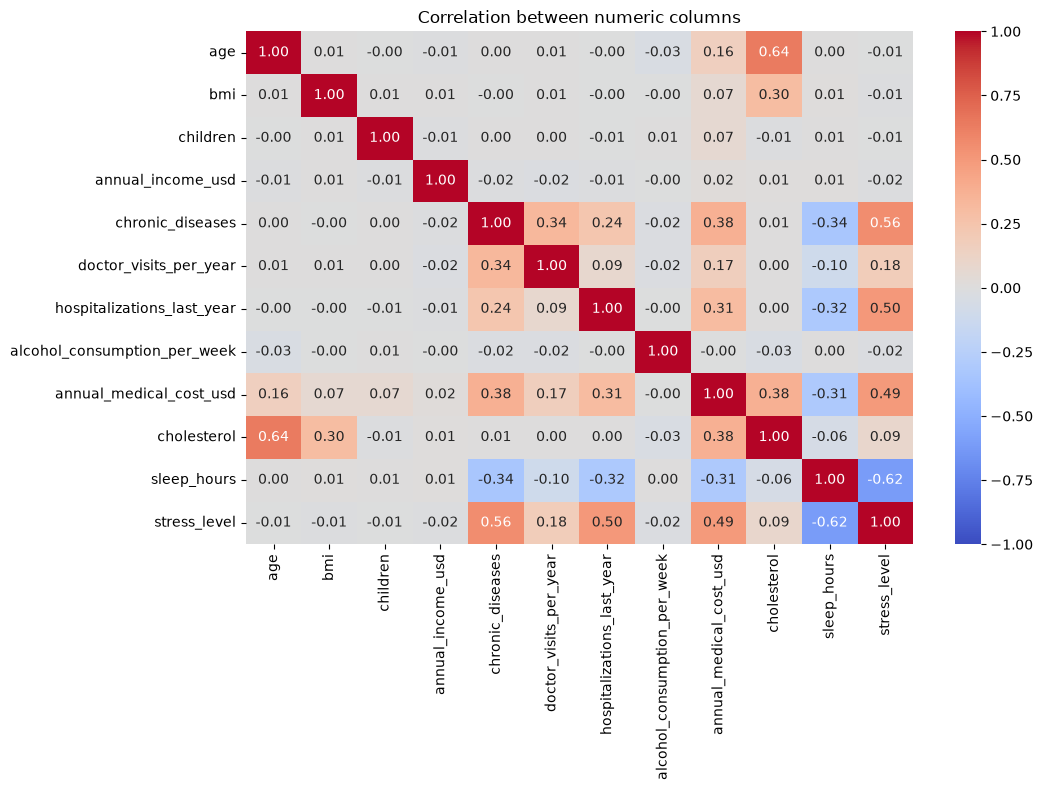

In [7]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation between numeric columns')
plt.tight_layout()
plt.savefig('../outputs/correlation_heatmap.png', dpi=150)
plt.show()

## 5. Prepare the data

In [8]:
data = df.drop(columns=['customer_id']).copy()

bp = data['blood_pressure'].str.split('/', expand=True).astype(float)
data['systolic_bp'] = bp[0]
data['diastolic_bp'] = bp[1]
data = data.drop(columns=['blood_pressure'])

print(data[['systolic_bp', 'diastolic_bp']].head())

   systolic_bp  diastolic_bp
0        149.0          87.0
1        131.0          74.0
2        126.0          76.0
3        144.0          77.0
4        150.0          78.0


In [9]:
text_cols = data.select_dtypes(exclude='number').columns.tolist()
print("Text columns:", text_cols)

data = pd.get_dummies(data, columns=text_cols, drop_first=True, dtype=float)
print("Shape after encoding:", data.shape)

Text columns: ['gender', 'smoker', 'region', 'occupation', 'exercise_level', 'insurance_plan', 'diabetes', 'marital_status']
Shape after encoding: (7500, 39)


In [10]:
X = data.drop(columns=['annual_medical_cost_usd'])
y = data['annual_medical_cost_usd']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train rows:", len(X_train))
print("Test rows:", len(X_test))

Train rows: 6000
Test rows: 1500


## 6. Train the model

In [11]:
model = LinearRegression()
model.fit(X_train, y_train)
print("Model trained")

Model trained


## 7. Evaluate the model

In [12]:
y_pred = model.predict(X_test)

r2 = metrics.r2_score(y_test, y_pred)
rmse = np.sqrt(metrics.mean_squared_error(y_test, y_pred))
mae = metrics.mean_absolute_error(y_test, y_pred)

print("Model: Linear Regression")
print(f"R2 on test set: {r2:.4f}")
print(f"RMSE: {rmse:.2f}")
print(f"MAE: {mae:.2f}")

Model: Linear Regression
R2 on test set: 0.8852
RMSE: 2516.85
MAE: 2019.69


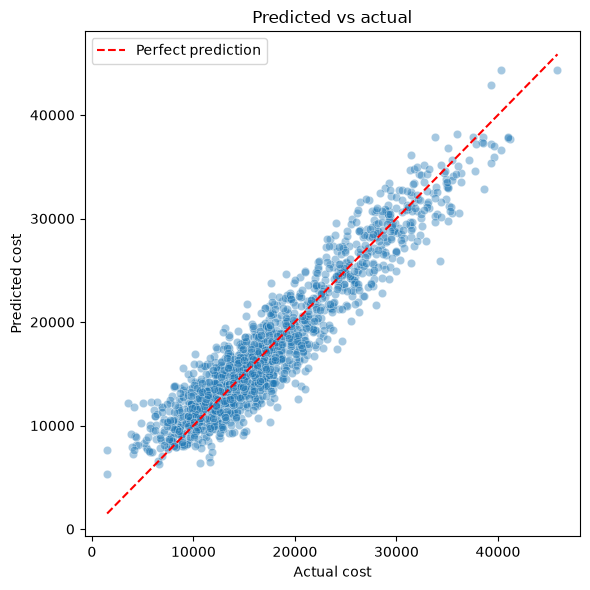

In [13]:
plt.figure(figsize=(6, 6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.4)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--', label='Perfect prediction')
plt.xlabel('Actual cost')
plt.ylabel('Predicted cost')
plt.title('Predicted vs actual')
plt.legend()
plt.tight_layout()
plt.savefig('../outputs/predicted_vs_actual.png', dpi=150)
plt.show()

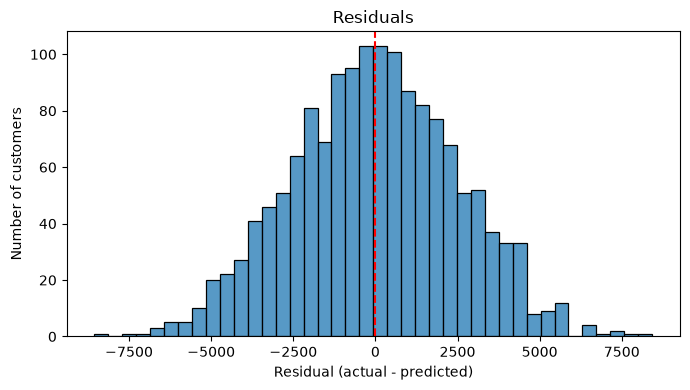

In [14]:
residuals = y_test - y_pred

plt.figure(figsize=(7, 4))
sns.histplot(residuals, bins=40)
plt.axvline(0, color='red', linestyle='--')
plt.xlabel('Residual (actual - predicted)')
plt.ylabel('Number of customers')
plt.title('Residuals')
plt.tight_layout()
plt.savefig('../outputs/residuals.png', dpi=150)
plt.show()

## 8. Which features matter most

smoker_Yes                    13881.2
insurance_plan_Gold            6893.5
insurance_plan_Premium         3530.5
hospitalizations_last_year     3178.3
exercise_level_Low             3120.3
chronic_diseases               2776.3
exercise_level_Moderate        1294.9
children                        487.7
occupation_Engineer             299.8
region_Northwest                190.0
region_Southeast                174.7
doctor_visits_per_year          164.3
occupation_Office Worker        150.7
occupation_Teacher              144.0
occupation_Lawyer               124.7
dtype: float64


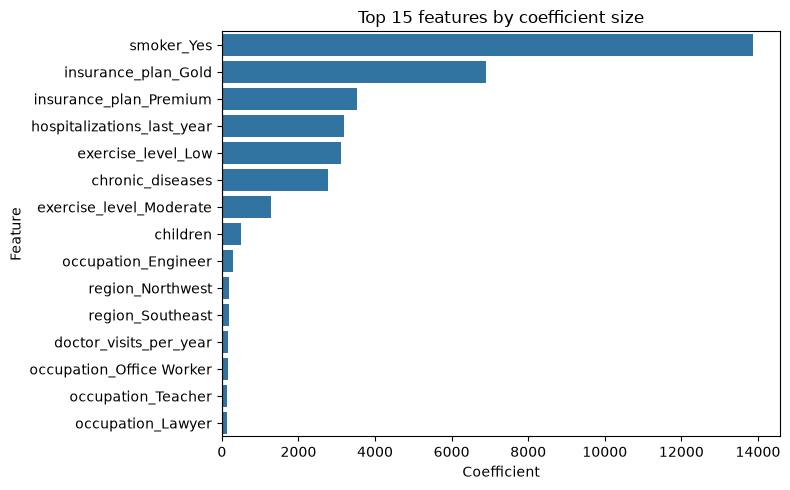

In [15]:
coef = pd.Series(model.coef_, index=X.columns)
top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(15)
print(top.round(1))

plt.figure(figsize=(8, 5))
sns.barplot(x=top.values, y=top.index)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Coefficient')
plt.ylabel('Feature')
plt.title('Top 15 features by coefficient size')
plt.tight_layout()
plt.savefig('../outputs/coefficients.png', dpi=150)
plt.show()

## 9. Save the predictions

In [16]:
results = pd.DataFrame({
    'customer_id': df.loc[y_test.index, 'customer_id'],
    'actual_cost': y_test,
    'predicted_cost': y_pred,
})
results['error'] = results['actual_cost'] - results['predicted_cost']
results.to_csv('../outputs/predictions.csv', index=False)
print(results.head())
print("Saved predictions.csv in outputs/")

     customer_id  actual_cost  predicted_cost        error
970    MIC100971     15298.91    17022.118444 -1723.208444
6279   MIC106280     14999.14    13102.571608  1896.568392
1859   MIC101860     11205.26    13442.230133 -2236.970133
6803   MIC106804     15385.60    13586.494942  1799.105058
6305   MIC106306     41144.58    37650.931525  3493.648475
Saved predictions.csv in outputs/
